In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

In [17]:
# Загрузка датасета
df = pd.read_csv("creditcard.csv")

# X = df.drop(["Class", "Time"], axis=1)
X = df[["V1", "V28"]].values
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Данные успешно отмасштабированы. Первые 3 строки:")
print(np.round(X_train_scaled[:3], 2))

Данные успешно отмасштабированы. Первые 3 строки:
[[-0.43  0.57]
 [-1.91  0.5 ]
 [-1.03  0.57]]


Значения примерно в одинаковом разбросе. Также убрал столбец Time, т.к. он не имеет никаких полезных данных

In [18]:
rng = np.random.RandomState(42)

idx_fraud = np.where(y_train == 1)[0]
idx_norm = np.where(y_train == 0)[0]
idx_norm_sample = rng.choice(idx_norm, size=20000, replace=False)

idx = np.concatenate([idx_fraud, idx_norm_sample])

X_train_small = X_train_scaled[idx]
y_train_small = y_train.iloc[idx]

Слишком много данных поэтому уменьшаем выборку 

In [19]:
svm_linear = SVC(
    kernel="linear",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_linear.fit(X_train_small, y_train_small)

y_pred_lin = svm_linear.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 99.8%


Точность получилась 99.8%, но дисбаланс классов не показывает реального качества: почти весь тест состоит из обычных транзакций.

In [20]:
svm_linear_С = SVC(
    kernel="linear",
    C=0.1,
    gamma="scale",
    random_state=42
)
svm_linear_С.fit(X_train_small, y_train_small)

y_pred_lin = svm_linear_С.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 99.8%


Изменение $C$ не повлияло на точность линейного SVM

In [21]:
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность SVM (RBF): {acc_rbf*100:.1f}%")
print(f"Из {len(X_train)} обучающих примеров опорных векторов - {len(svm_rbf.support_vectors_)}")

Точность SVM (RBF): 99.8%
Из 213605 обучающих примеров опорных векторов - 1226


Точность осталась та же из-за дисбаланса данных и не показывает реального качества. Опорных векторов очень мало - границу определяет малое количество точек. В датасете недостаточно данных мошеннеческих операций (492 мошеннические операции (ctrl+f = "1")), из-за чего модели тяжело понять паттерны. Процент опорных векторов ~0,574%

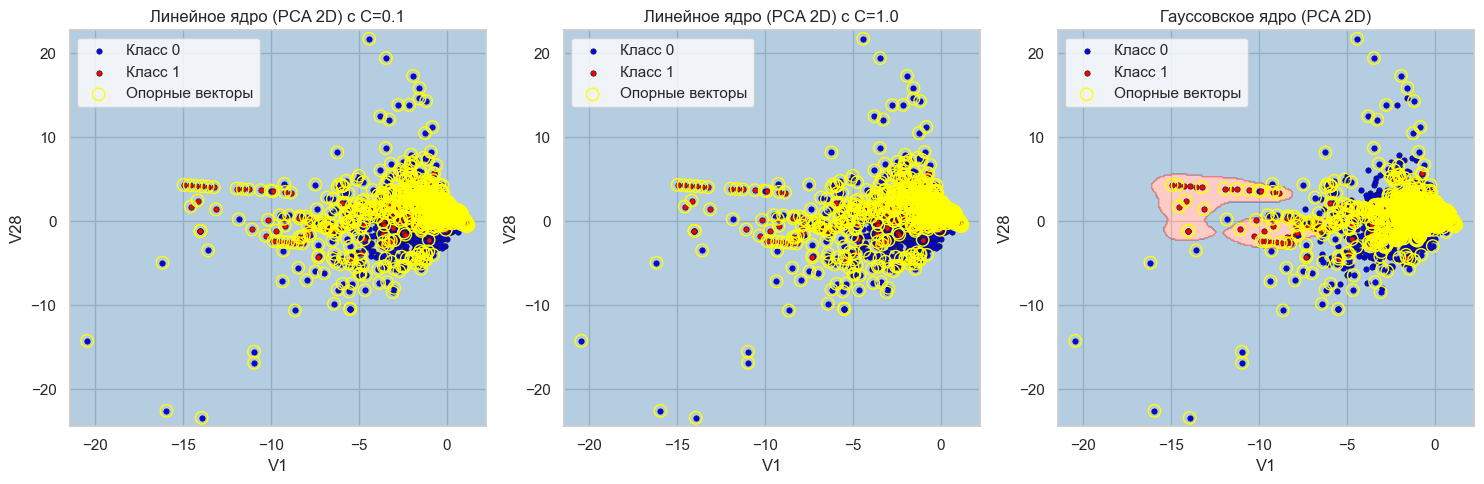

In [24]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

pca = PCA(n_components=2)
X_small_2d = pca.fit_transform(X_train_small)
X_test_2d = pca.transform(X_test_scaled)

svm_lin_2d = SVC(kernel="linear", C=1.0, random_state=42).fit(X_small_2d, y_train_small)
svm_lin_2d_small = SVC(kernel="linear", C=0.1, random_state=42).fit(X_small_2d, y_train_small)
svm_rbf_2d = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42).fit(X_small_2d, y_train_small)

def plot_decision_boundary(model, X_set, y_set, ax, title):
    X1, X2 = np.meshgrid(
        np.linspace(X_set[:,0].min()-1, X_set[:,0].max()+1, 300),
        np.linspace(X_set[:,1].min()-1, X_set[:,1].max()+1, 300),
    )
    Z = model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)
    ax.contourf(X1, X2, Z, alpha=0.4, cmap=ListedColormap(("steelblue", "salmon")))

    for c, color in zip([0, 1], ["blue", "red"]):
        mask = (y_set == c)
        ax.scatter(X_set[mask,0], X_set[mask,1], color=color, s=15,
                   edgecolors="k", linewidth=0.5, label=f"Класс {c}")

    ax.scatter(model.support_vectors_[:,0], model.support_vectors_[:,1],
               s=80, facecolors="none", edgecolors="yellow", label="Опорные векторы")
    ax.set_title(title)
    ax.set_xlabel("V1")
    ax.set_ylabel("V28")
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_decision_boundary(svm_lin_2d_small, X_small_2d, y_train_small.values, axes[0], "Линейное ядро (PCA 2D) c C=0.1")
plot_decision_boundary(svm_lin_2d, X_small_2d, y_train_small.values, axes[1], "Линейное ядро (PCA 2D) c C=1.0")
plot_decision_boundary(svm_rbf_2d, X_small_2d, y_train_small.values, axes[2], "Гауссовское ядро (PCA 2D)")
plt.tight_layout()
plt.show()

Линейное ядро отрезало обычные транзакции (синие точки) от мошеннеческих (красные точки), но на 99.8% как было выявлено ранее, т.к. часть красных точек находятся с обычными транзакциями и часть синих точек с мошеннеческими.
Гаусовское ядро гибко обводит обычные транзакции. Но тоже с 99.8%, ведь часть точек выделена не верно


Изменение $C$ не выдало иного результата, поэтому можно сделать вывод, что оно не влияет на результат